<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/02_time_series/05_anomaly_detection_nyc_taxi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚕 Application · Anomaly detection: what disturbed New York's taxis?

Every 30 minutes, New York's Taxi & Limousine Commission records how many passengers took a yellow cab. Day after
day, the city breathes with the same rhythm: quiet at 4 a.m., rush in the evening, busier Fridays. But sometimes
the rhythm breaks.

In 2015, the company Numenta released the **Numenta Anomaly Benchmark (NAB)**: 58 real-world series (server CPU,
machine temperatures, tweets, traffic…) with human-labelled anomalies, to compare algorithms that must raise an alarm
*while* data streams in. One of its stars is this taxi series, from July 2014 to January 2015, with **five known
events** hidden inside. We won't tell you which ones yet. 🤫

**Why anomaly detection matters:** fraud on a bank card, a machine about to break, a cyber-attack, a sensor gone
crazy… Anomalies are rare and rarely labelled, so we usually detect them **without supervision**: learn what
"normal" looks like, and flag what deviates from it.

| Phase | Why |
|---|---|
| 1. Load and look | understand the normal rhythm |
| 2. Types of anomalies | point vs **contextual** anomalies |
| 3. Global z-score | the naive approach, and why it fails |
| 4. Rolling z-score | "unusual compared to the last few days" |
| 5. Seasonal residuals (STL) | "unusual for a Tuesday at 6 p.m." |
| 6. Isolation Forest | a machine-learning detector on engineered features |
| 7. Evaluation against the known events | detections vs false alarms |

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

quest("What disturbed New York's taxis?", chapter="Track 2 · Time series · Anomaly detection", xp=250)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · What disturbed New York's taxis?
   Track 2 · Time series · Anomaly detection
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load the series 📥

In [3]:
NAB = "https://raw.githubusercontent.com/numenta/NAB/master"
csv = download(f"{NAB}/data/realKnownCause/nyc_taxi.csv", DATA_DIR / "nab" / "nyc_taxi.csv")
labels_file = download(f"{NAB}/labels/combined_windows.json", DATA_DIR / "nab" / "combined_windows.json")

taxi = pd.read_csv(csv, parse_dates=["timestamp"], index_col="timestamp")["value"]
windows = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in json.loads(labels_file.read_text())["realKnownCause/nyc_taxi.csv"]]
print(f"{len(taxi)} half-hours from {taxi.index.min():%Y-%m-%d} to {taxi.index.max():%Y-%m-%d}")
print(f"{len(windows)} labelled anomaly windows (kept secret for now 🤫)")

10320 half-hours from 2014-07-01 to 2015-01-31
5 labelled anomaly windows (kept secret for now 🤫)


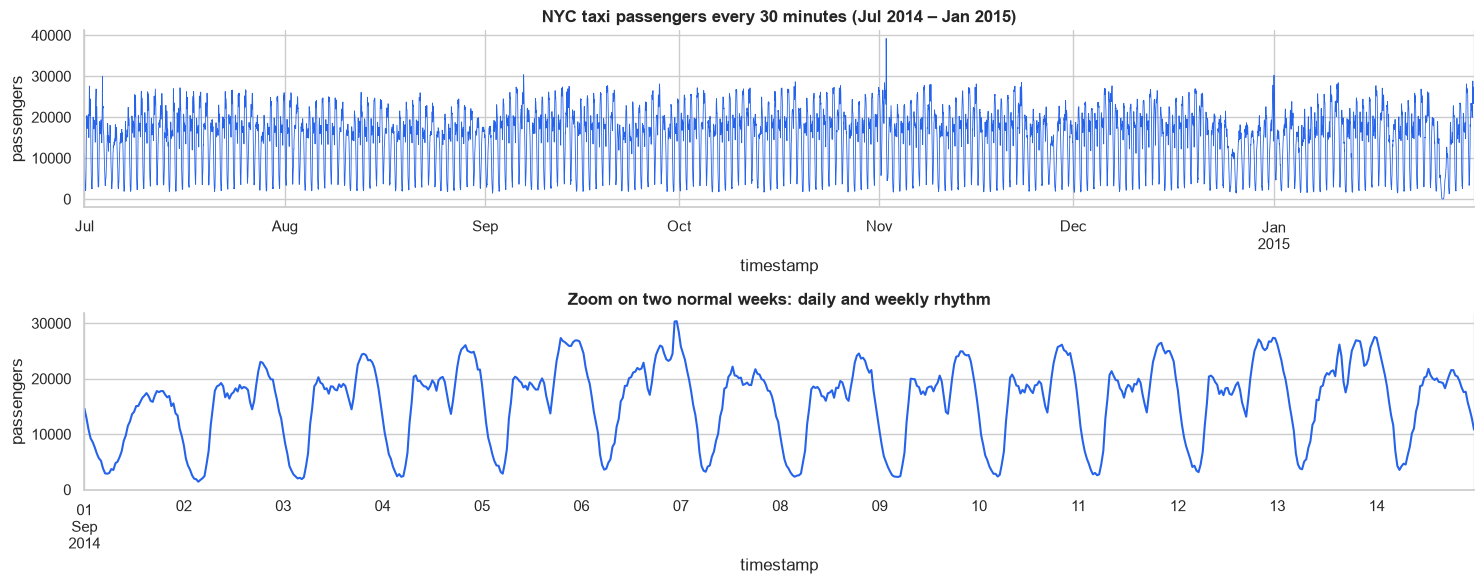

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 6))
taxi.plot(ax=axes[0], lw=0.6, title="NYC taxi passengers every 30 minutes (Jul 2014 – Jan 2015)")
taxi["2014-09-01":"2014-09-14"].plot(ax=axes[1], title="Zoom on two normal weeks: daily and weekly rhythm")
for ax in axes: ax.set_ylabel("passengers")
plt.tight_layout(); plt.show()

Each day has a deep night trough and an evening peak; weekends have a different shape (late nights, no morning
rush). Can you already spot unusual days in the full chart? Some anomalies are obvious, others hide in plain sight.

## 2. Two kinds of anomalies 🧠

- **Point anomaly**: a value that is extreme *in absolute terms* (a huge spike or a drop to almost zero).
- **Contextual anomaly**: a value that is perfectly normal in general but abnormal **for its context**. 10 000
  passengers is normal on a Monday at 7 p.m., but very strange on a Monday at 4 a.m.

Time series are full of contextual anomalies, so our detectors must know the *context*: the time of day, the day of
the week, recent history.

We will build several detectors. Each produces an **anomaly score** per half-hour (higher = stranger). For fairness,
every detector raises the same number of alarms: the **50 most anomalous half-hours** (about 0.5% of the data).

In [5]:
N_ALARMS = 50
scores = {}

def plot_detector(name, score, ax=None):
    alarms = score.nlargest(N_ALARMS).index
    ax = ax or plt.subplots(figsize=(15, 3.2))[1]
    taxi.plot(ax=ax, lw=0.5, color="gray")
    ax.scatter(alarms, taxi[alarms], color="red", s=14, zorder=3, label=f"top {N_ALARMS} alarms")
    ax.set(title=name, ylabel="passengers"); ax.legend(loc="upper left")
    return ax

## 3. Global z-score: "far from the average" 📏

The z-score measures how many standard deviations a value is from the mean: $z = (x - \mu) / \sigma$. Values with
$|z| > 3$ are classic "outliers".

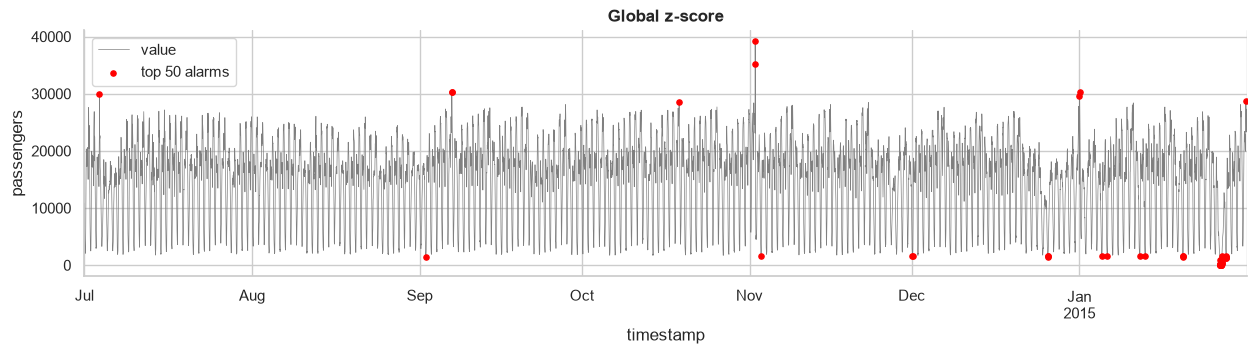

Days with the most alarms:
2015-01-27    19
2015-01-28     5
2015-01-26     3
2014-12-26     3
2015-01-20     3


In [6]:
z_global = (taxi - taxi.mean()) / taxi.std()
scores["Global z-score"] = z_global.abs()
plot_detector("Global z-score", scores["Global z-score"]); plt.show()
print("Days with the most alarms:")
print(pd.Series(scores["Global z-score"].nlargest(N_ALARMS).index.date).value_counts().head(5).to_string())

More than half of the alarms pile up on **one** dramatic episode at the end of January, when passenger counts
collapse to almost zero: an extreme *point* anomaly, impossible to miss. The other alarms land on the busiest evenings
or the quietest nights of ordinary days, i.e. the **normal** extremes of the daily cycle. A global threshold ignores
context: it cannot see an anomaly that stays within the usual range.

## 4. Rolling z-score: "unusual compared to the same moment of recent weeks" 🪟

Compare each value with a **moving window** of recent history. To respect both the daily *and* weekly cycles, we
compare each half-hour with **the same half-hour of the same weekday over the previous 4 weeks** (Tuesday 6 p.m. vs the
last four Tuesdays at 6 p.m.).

The first 4 weeks have no complete history: the detector needs a **warm-up** period, so we give them a score of 0.

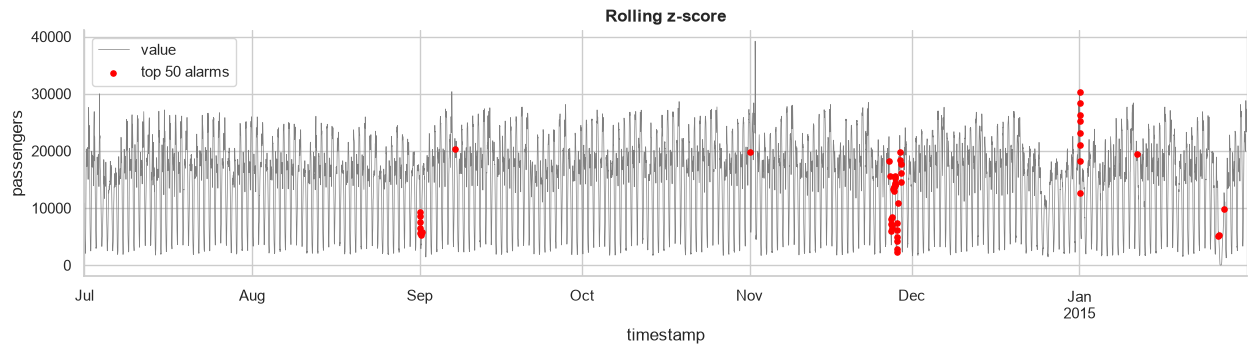

In [7]:
WEEK = 48 * 7                                                                  # 48 half-hours per day
same_slot = pd.concat([taxi.shift(WEEK * k) for k in range(1, 5)], axis=1)
z_rolling = (taxi - same_slot.mean(axis=1)) / (same_slot.std(axis=1) + 50)    # +50 avoids dividing by ~0 at night
z_rolling[same_slot.count(axis=1) < 4] = 0                                     # warm-up: not enough history
scores["Rolling z-score (same slot, last 4 weeks)"] = z_rolling.abs()
plot_detector("Rolling z-score", scores["Rolling z-score (same slot, last 4 weeks)"]); plt.show()

Alarms now gather on a handful of specific days instead of every evening peak. The price: a warm-up period, and a
reference (the last 4 weeks) that can itself contain anomalies.

## 5. Seasonal residuals with STL: "unusual for a Tuesday at 6 p.m." 🔬

STL (seen in the CO₂ quest) splits the series into trend + seasonality + residual. With a **weekly** period
(48 × 7 = 336 half-hours), the seasonal part captures the full weekly rhythm (weekday and weekend shapes). What is left,
the **residual**, is everything the normal rhythm cannot explain: exactly what we look for. We use `robust=True` so
that the anomalies themselves don't distort the estimated rhythm.

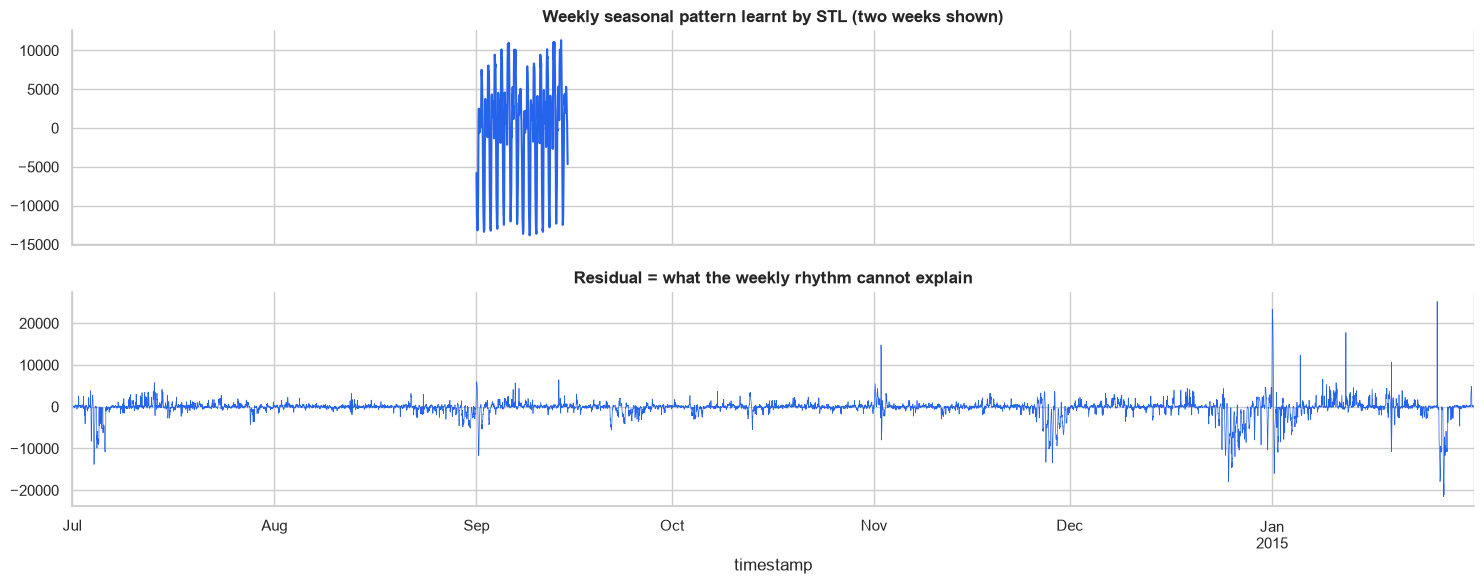

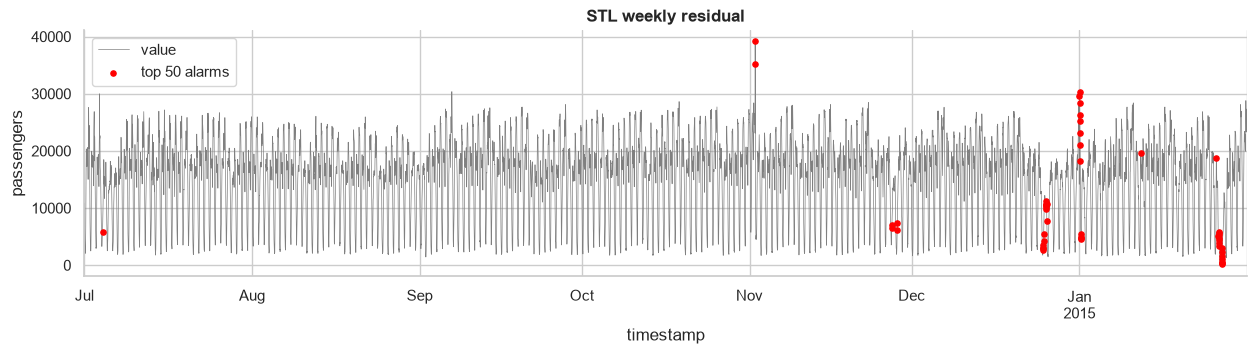

In [8]:
from statsmodels.tsa.seasonal import STL
stl = STL(taxi, period=48 * 7, robust=True).fit()
resid = stl.resid
scores["STL weekly residual"] = (resid - resid.median()).abs() / resid.std()

fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
stl.seasonal["2014-09-01":"2014-09-14"].plot(ax=axes[0], title="Weekly seasonal pattern learnt by STL (two weeks shown)")
resid.plot(ax=axes[1], lw=0.5, title="Residual = what the weekly rhythm cannot explain")
plt.tight_layout(); plt.show()
plot_detector("STL weekly residual", scores["STL weekly residual"]); plt.show()

## 6. Isolation Forest: let a model find the odd ones 🌲

**Isolation Forest** (Liu, Ting & Zhou, 2008) builds random trees that split the data with random cuts. An anomaly is
*easy to isolate*: few cuts are needed to separate it from everything else, so it ends up close to the root of the
trees. Normal points, surrounded by similar points, need many cuts.

The model is only as good as the features describing each half-hour. We give it the context:

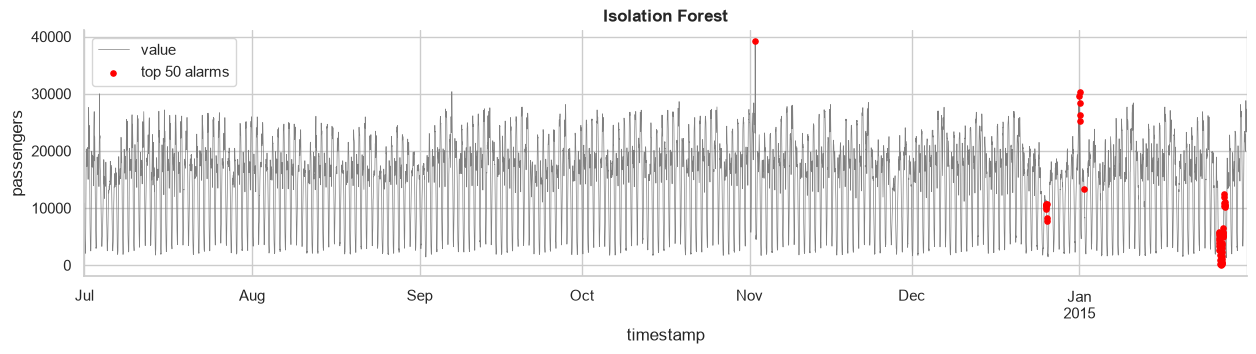

✅ Checkpoint · taxi/detectors (+60 XP)
   ██████████████░░░░░░░░░░ 60/100 XP


In [9]:
from sklearn.ensemble import IsolationForest

feat = pd.DataFrame({
    "value": taxi,
    "hour": taxi.index.hour + taxi.index.minute / 60,
    "dayofweek": taxi.index.dayofweek,
    "vs_last_week": taxi - taxi.shift(48 * 7),                         # change vs same slot one week earlier
    "vs_yesterday": taxi - taxi.shift(48),
    "daily_total_ratio": taxi.rolling(48).sum() / taxi.shift(48 * 7).rolling(48).sum(),   # last 24 h vs same 24 h last week
    "stl_resid": resid,
}).bfill()

iso = IsolationForest(n_estimators=300, contamination="auto", random_state=SEED).fit(feat)
scores["Isolation Forest"] = pd.Series(-iso.score_samples(feat), index=taxi.index)   # higher = more anomalous
plot_detector("Isolation Forest", scores["Isolation Forest"]); plt.show()
checkpoint("taxi/detectors", xp=60)

## 7. The reveal: what really happened? 🎬

Here are NAB's five labelled windows. Each window is centred on a real event:

| Event | Date |
|---|---|
| 🏃 New York City Marathon | November 2, 2014 |
| 🦃 Thanksgiving | November 27, 2014 |
| 🎄 Christmas | December 25, 2014 |
| 🎆 New Year's Eve / Day | December 31, 2014 – January 1, 2015 |
| ❄️ Blizzard (travel ban, the city shut down) | January 26-27, 2015 |

**How do we score a detector?** In streaming anomaly detection we care about **events**, not individual points: an
event is *detected* if at least one alarm falls inside its window. Alarms outside every window are **false alarms**.
(NAB's official score also rewards *early* detection; we keep a simpler version.)

In [10]:
EVENTS = ["Marathon", "Thanksgiving", "Christmas", "New Year", "Blizzard"]

def evaluate(score):
    alarms = score.nlargest(N_ALARMS).index
    in_window = np.zeros(len(alarms), dtype=bool)
    detected = []
    for (start, end), event in zip(windows, EVENTS):
        hit = (alarms >= start) & (alarms <= end)
        in_window |= hit
        detected.append(hit.any())
    false_alarm_days = pd.Series(alarms[~in_window].date).nunique()
    return detected, in_window.mean(), false_alarm_days

lb = Leaderboard("nyc_taxi_anomalies", metric="events_detected")
rows = {}
for name, score in scores.items():
    detected, precision, fa_days = evaluate(score)
    rows[name] = dict(zip(EVENTS, ["✅" if d else "❌" for d in detected]))
    lb.add(name, sum(detected), alarm_precision=round(precision, 2), false_alarm_days=fa_days)
display(pd.DataFrame(rows).T)
lb.show()

📋 Global z-score: events_detected = 4.00000
📋 Rolling z-score (same slot, last 4 weeks): events_detected = 4.00000
📋 STL weekly residual: events_detected = 5.00000  👑 new best!
📋 Isolation Forest: events_detected = 4.00000


,Marathon,Thanksgiving,Christmas,New Year,Blizzard
Global z-score,✅,❌,✅,✅,✅
"Rolling z-score (same slot, last 4 weeks)",✅,✅,❌,✅,✅
STL weekly residual,✅,✅,✅,✅,✅
Isolation Forest,✅,❌,✅,✅,✅


,,model,events_detected,alarm_precision,false_alarm_days
rank,,,,,
1,🥇,STL weekly residual,5.0,0.96,2
2,🥈,Global z-score,4.0,0.70,11
3,🥉,"Rolling z-score (same slot, last 4 weeks)",4.0,0.82,3
4,,Isolation Forest,4.0,1.00,0


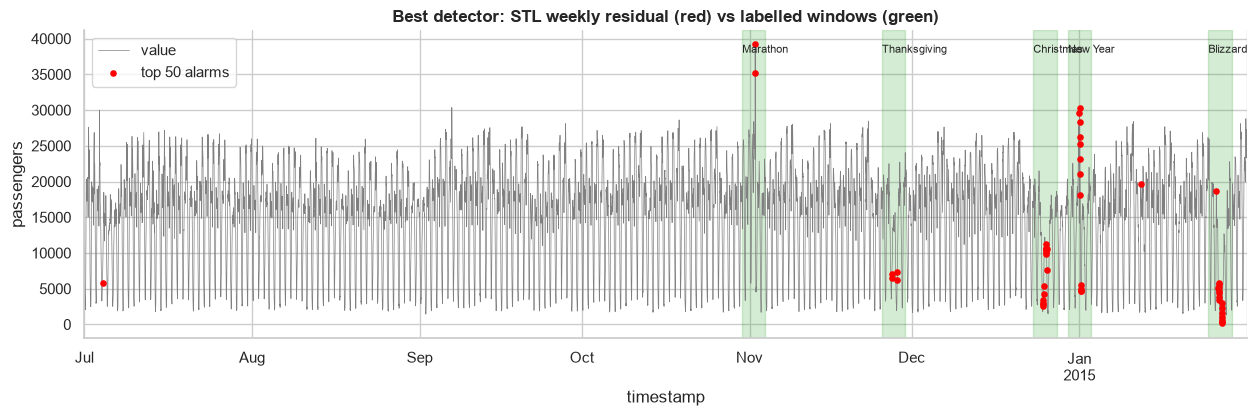

In [11]:
fig, ax = plt.subplots(figsize=(15, 4))
best = lb.best()["model"]
plot_detector(f"Best detector: {best} (red) vs labelled windows (green)", scores[best], ax=ax)
for (start, end), event in zip(windows, EVENTS):
    ax.axvspan(start, end, color="tab:green", alpha=0.2)
    ax.text(start, taxi.max() * 0.97, event, fontsize=8)
plt.show()

**Lessons from the reveal**
- Counting "events detected" is not enough: look at **where the alarms go**. The global z-score spends most of its
  budget on the blizzard and raises alarms on many ordinary days. Context is everything.
- Detectors that compare with the **normal rhythm** (same slot in previous weeks, weekly seasonality) concentrate
  their alarms on real events: higher precision, fewer false-alarm days.
- Some events are *drops* (the blizzard shut the city, Thanksgiving empties offices), others are *shifts* (New
  Year's night is busy at 3 a.m.). A good detector catches both directions.
- "False alarms" are not always false. Check the dates flagged outside the windows below: holidays such as
  **July 4th** (Independence Day) or **September 1st** (Labor Day) are real disruptions that NAB simply did not label.
  In real projects, every alarm reviewed by a human improves the labels.

In [12]:
for name, score in scores.items():
    alarms = score.nlargest(N_ALARMS).index
    outside = [d for d in alarms if not any(s <= d <= e for s, e in windows)]
    print(f"{name:<45} alarms outside windows on: {sorted({d.strftime('%b %d') for d in outside})}")

Global z-score                                alarms outside windows on: ['Dec 01', 'Jan 05', 'Jan 06', 'Jan 12', 'Jan 13', 'Jan 20', 'Jan 31', 'Jul 03', 'Oct 18', 'Sep 02', 'Sep 06']
Rolling z-score (same slot, last 4 weeks)     alarms outside windows on: ['Jan 11', 'Sep 01', 'Sep 07']
STL weekly residual                           alarms outside windows on: ['Jan 12', 'Jul 04']
Isolation Forest                              alarms outside windows on: []


## 🏁 Quest complete!

### 🚀 Your turn (bonus XP)
1. Change `N_ALARMS` to 20 and 100. Which detector stays robust? This is the classic **precision vs recall** trade-off.
2. Add a holiday calendar feature to the Isolation Forest. Does it reduce false alarms, or hide real anomalies?
3. Try another NAB series, e.g. `realKnownCause/machine_temperature_system_failure.csv` (an industrial machine that
   breaks down) or `realKnownCause/ambient_temperature_system_failure.csv`.
4. Make it **streaming**: recompute the rolling z-score only with past data (it already is!) and STL on an expanding
   window. Which detectors could run live?

In [13]:
checkpoint("taxi/complete", xp=190)
badge("Anomaly Hunter", "🚨")
progress()

✅ Checkpoint · taxi/complete (+190 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██████████████████░░░░░░ 250/300 XP
╔═══════════════════════════════════╗
║ 🚨  BADGE UNLOCKED: Anomaly Hunter ║
╚═══════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 2
Badges: 🚨 Anomaly Hunter
